# Proyecto final — Modelos y Simulación II

**Universidad de Antioquia · Facultad de Ingeniería**

- **Equipo:** Samuel Puerta Patiño, Simón Berrio Gaviria, Juan Estiven Carmona Muñoz
- **Grupo:** 5 · **Semestre:** 2026-2 · **Dataset:** *Financial Transactions & Fraud Detection* (Kaggle)

## Protocolo temporal y probabilidades de historial (asesoría con el profesor)

Este notebook incorpora las recomendaciones de la asesoría con el profesor. Complementa los notebooks 01 a 05: repite la evaluación de los seis modelos con un **protocolo temporal** (entrenar con el pasado y probar con el futuro, sin particiones aleatorias) y con nuevas variables de historial expresadas como **probabilidades entre 0 y 1**. Sus resultados alimentan la discusión final del notebook 07.

| ID | Recomendación del profesor | Apartado |
|---|---|---|
| R1, R6 | Tratar el problema como serie temporal; no usar particiones aleatorias | 3 (partición única y *backtesting* mensual) y 4 (comparación con la partición aleatoria) |
| R2 | Detectar anomalías de uso respecto al historial del usuario | 1 y 5 |
| R3 | Moneda inusual (por ejemplo, SOL en un usuario que siempre usa USD) | 1.3 (documentación) y 6 (control positivo simulado) |
| R4 | Convertir cada atributo en una probabilidad 0–1 de frecuencia en el historial, sin incluir la propia transacción | 1 |
| R5 | No descartar ninguna variable | 2 y 7 |
| R7 | Isolation Forest y One-Class SVM | 5 |
| R8 | Evaluar con y sin `risk_score` | Todo el notebook |

### Decisiones sobre los puntos ambiguos

1. **No se descartan variables.** El modelo final recibe todas las variables; el análisis de reducción del notebook 05 queda como resultado complementario.
2. **`currency` se documenta y se usa.** Solo toma el valor USD, así que su probabilidad es prácticamente constante. Se incluye para cumplir con «no descartar», y el apartado 6 muestra con un control positivo simulado que el método sí detectaría una moneda nueva.
3. **Se prueban dos estrategias temporales:** una partición única 80/20 y un *backtesting* mensual (febrero a agosto de 2026).
4. **El historial usa toda la historia previa** como opción principal, y se compara con una **ventana de 30 días**.
5. **«OJVM» se interpretó como One-Class SVM** (por confirmar con el profesor).

> **Garantía causal.** Toda variable de historial de una transacción se calcula solo con transacciones **anteriores**; el apartado 1.2 lo verifica empíricamente.

> **Ejecución.** Requiere `data/caracteristicas.csv` (lo genera el notebook 01) y `data/synthetic_financial_transactions.csv`. Ejecutar desde la carpeta `notebooks/`. Las búsquedas de hiperparámetros y los reentrenamientos usan `N_JOBS` procesos (celda de configuración); la ejecución completa toma del orden de 40 minutos con 6 procesos.

## Configuración

In [1]:
import os
from pathlib import Path
import time
import warnings

os.environ["PYTHONWARNINGS"] = "ignore"

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from joblib import Parallel, delayed
from scipy import stats
from imblearn.ensemble import BalancedRandomForestClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, IsolationForest
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import GridSearchCV, RepeatedStratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import OneClassSVM, SVC
from sklearn.utils.class_weight import compute_sample_weight
from threadpoolctl import threadpool_limits

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

RANDOM_STATE = 42
N_JOBS = 6
N_ARBOLES = 200
PSEUDO = 2.0
VENTANA_DIAS = 30
MIN_GLOBAL = 30
UMBRAL_RARO = 0.1
REPLICAS_BOOTSTRAP = 1000
np.random.seed(RANDOM_STATE)
threadpool_limits(limits=N_JOBS)

DATA_PATH = Path("../data/caracteristicas.csv")
RAW_PATH = Path("../data/synthetic_financial_transactions.csv")
FIG_DIR = Path("../report/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)
COLORES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#8a5cd0"]
COLOR_REF = "#52514e"


def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.pdf", bbox_inches="tight")
    plt.savefig(FIG_DIR / f"{name}.png", dpi=200, bbox_inches="tight")

In [2]:
def cargar_datos():
    caract = pd.read_csv(DATA_PATH, parse_dates=["timestamp"])
    crudo = pd.read_csv(RAW_PATH, usecols=["transaction_id", "amount", "currency"])
    datos = caract.merge(crudo, on="transaction_id", how="left", validate="one_to_one")
    assert datos["amount"].notna().all()
    datos = datos.sort_values("timestamp", kind="stable").reset_index(drop=True)
    datos["franja"] = pd.cut(datos["timestamp"].dt.hour, [-1, 5, 11, 17, 23],
                             labels=["00-05", "06-11", "12-17", "18-23"]).astype(str)
    return datos


base = cargar_datos()
Y = base["is_fraud"].to_numpy()
print(f"Transacciones: {len(base):,} | fraudes: {Y.sum()} ({100 * Y.mean():.2f} %) | "
      f"periodo: {base['timestamp'].min():%Y-%m-%d} a {base['timestamp'].max():%Y-%m-%d}")

Transacciones: 10,000 | fraudes: 126 (1.26 %) | periodo: 2025-08-26 a 2026-08-26


## 1. Probabilidades de historial (R2, R3 y R4)

Para cada transacción y cada atributo (`category`, `device_type`, `payment_method`, `account_type`, `currency` y la franja horaria) se calcula

$$p=\frac{n_v+m\,p_{\text{global}}}{n+m},$$

donde $n$ es el número de transacciones **previas** del usuario, $n_v$ cuántas de ellas tuvieron el mismo valor que la actual, $p_{\text{global}}$ la frecuencia global previa del valor y $m = 2$ pseudo-transacciones de contracción, como en el notebook 01, porque cada usuario tiene en promedio 4,7 transacciones. La frecuencia global se suaviza con Laplace usando solo los valores vistos hasta ese momento: $p_{\text{global}} = (c_v + 1)/(N + K + 1)$, con $c_v$ las apariciones previas del valor, $N$ las transacciones previas de toda la base y $K$ los valores distintos vistos. El resultado está en $[0, 1]$: un valor nunca usado por el usuario tiene una probabilidad cercana a 0.

Además se construyen:

- **Probabilidad 0–1 del monto:** p-valor bilateral de $z$, con una normal sobre `amount_log` cuya media y varianza se contraen hacia el perfil global previo (como `z_monto` en el notebook 01).
- **Combinaciones:** dispositivo × medio de pago, categoría × dispositivo y cuenta × medio de pago.
- **Resúmenes:** `p_min` (la probabilidad más baja de la transacción) y `n_raros` (cuántos atributos tienen $p < 0{,}1$).
- **Recencia:** `log(1 + horas)` desde la última vez que el usuario usó ese valor; queda vacía si nunca lo usó.
- **Versión con ventana:** las mismas probabilidades con solo los últimos 30 días del usuario (sufijo `_w30`).

In [3]:
ATRIBUTOS = ["category", "device_type", "payment_method", "account_type", "currency", "franja"]
COMBINACIONES = {"disp_metodo": ("device_type", "payment_method"), "cat_disp": ("category", "device_type"),
                 "cuenta_metodo": ("account_type", "payment_method")}
RECENCIA = ["category", "device_type", "payment_method", "account_type", "franja"]


def valores_historial(datos):
    v = datos[ATRIBUTOS].astype(str)
    for nombre, (a, b) in COMBINACIONES.items():
        v[nombre] = v[a] + " | " + v[b]
    return v


def prob_global(serie):
    vistas = serie.groupby(serie).cumcount().to_numpy()
    nuevo = (~serie.duplicated()).to_numpy()
    distintos_previos = np.cumsum(nuevo) - nuevo
    return (vistas + 1) / (np.arange(len(serie)) + distintos_previos + 1)


def construir_historial(datos, ventana_dias=VENTANA_DIAS):
    valores = valores_historial(datos)
    claves = list(valores.columns)
    previa_global = {c: prob_global(valores[c]) for c in claves}
    codigos = {c: pd.factorize(valores[c])[0] for c in claves}
    x = datos["amount_log"].to_numpy(dtype=float)
    media_g = pd.Series(x).expanding(MIN_GLOBAL).mean().shift().to_numpy()
    seg_mom_g = pd.Series(x ** 2).expanding(MIN_GLOBAL).mean().shift().to_numpy()
    horas = (datos["timestamp"] - datos["timestamp"].min()).dt.total_seconds().to_numpy() / 3600
    n = len(datos)
    salida = {}
    for sufijo in ("", "_w30"):
        for c in claves + ["monto"]:
            salida[f"p_{c}{sufijo}"] = np.full(n, np.nan)
    for c in RECENCIA:
        salida[f"rec_{c}"] = np.full(n, np.nan)
    for filas in datos.groupby("user_id", sort=False).indices.values():
        filas = np.sort(filas)
        t = horas[filas]
        previa = np.tri(len(filas), k=-1, dtype=bool)
        reciente = previa & ((t[:, None] - t[None, :]) <= 24 * ventana_dias)
        for mascara, sufijo in ((previa, ""), (reciente, "_w30")):
            n_prev = mascara.sum(axis=1)
            for c in claves:
                cod = codigos[c][filas]
                n_valor = (mascara & (cod[:, None] == cod[None, :])).sum(axis=1)
                salida[f"p_{c}{sufijo}"][filas] = (n_valor + PSEUDO * previa_global[c][filas]) / (n_prev + PSEUDO)
            xu = x[filas]
            media = (mascara @ xu + PSEUDO * media_g[filas]) / (n_prev + PSEUDO)
            varianza = np.clip((mascara @ xu ** 2 + PSEUDO * seg_mom_g[filas]) / (n_prev + PSEUDO) - media ** 2, 1e-6, None)
            salida[f"p_monto{sufijo}"][filas] = 2 * stats.norm.sf(np.abs((xu - media) / np.sqrt(varianza)))
        posiciones = np.arange(len(filas))
        for c in RECENCIA:
            cod = codigos[c][filas]
            igual = previa & (cod[:, None] == cod[None, :])
            ultimo = np.where(igual, posiciones[None, :], -1).max(axis=1)
            salida[f"rec_{c}"][filas] = np.where(ultimo >= 0, np.log1p(t - t[np.maximum(ultimo, 0)]), np.nan)
    hist = pd.DataFrame(salida, index=datos.index)
    for sufijo in ("", "_w30"):
        hist[f"p_monto{sufijo}"] = hist[f"p_monto{sufijo}"].fillna(1.0)
        probabilidades = [f"p_{c}{sufijo}" for c in claves + ["monto"]]
        hist[f"p_min{sufijo}"] = hist[probabilidades].min(axis=1)
        hist[f"n_raros{sufijo}"] = (hist[probabilidades] < UMBRAL_RARO).sum(axis=1).astype(float)
    return hist


inicio = time.time()
historial = construir_historial(base)
df = base.join(historial)
CLAVES = list(valores_historial(base.head()).columns)
P_COMPLETO = [f"p_{c}" for c in CLAVES + ["monto"]]
P_W30 = [f"{c}_w30" for c in P_COMPLETO]
HIST_COMPLETO = P_COMPLETO + ["p_min", "n_raros"]
HIST_W30 = P_W30 + ["p_min_w30", "n_raros_w30"]
REC = [f"rec_{c}" for c in RECENCIA]
VARS_HIST = HIST_COMPLETO + REC + HIST_W30
print(f"Variables nuevas de historial: {len(VARS_HIST)} ({time.time() - inicio:.0f} s)")
df[VARS_HIST].describe().T[["count", "mean", "std", "min", "max"]]

Variables nuevas de historial: 29 (1 s)


,count,mean,std,min,max
p_category,"10,000.000",0.155,0.125,0.007,1.000
p_device_type,"10,000.000",0.379,0.223,0.012,1.000
p_payment_method,"10,000.000",0.296,0.160,0.015,1.000
p_account_type,"10,000.000",0.382,0.170,0.021,1.000
p_currency,"10,000.000",0.999,0.006,0.667,1.000
p_franja,"10,000.000",0.244,0.122,0.038,1.000
p_disp_metodo,"10,000.000",0.113,0.113,0.001,1.000
p_cat_disp,"10,000.000",0.058,0.078,0.001,1.000
p_cuenta_metodo,"10,000.000",0.114,0.104,0.002,1.000
p_monto,"10,000.000",0.458,0.298,0.000,1.000


### 1.2 Verificación causal

Si las variables solo miran el pasado, recalcularlas con una base **truncada** (solo las primeras 6.000 transacciones) debe dar exactamente los mismos valores para esas filas.

In [4]:
recortada = construir_historial(base.iloc[:6000].reset_index(drop=True))
diferencia = 0.0
for c in VARS_HIST:
    a, b = recortada[c].to_numpy(), historial[c].iloc[:6000].to_numpy()
    assert (np.isnan(a) == np.isnan(b)).all(), c
    diferencia = max(diferencia, np.nanmax(np.abs(a - b)))
print(f"Máxima diferencia al truncar el futuro: {diferencia:.2e}")
assert diferencia < 1e-9

Máxima diferencia al truncar el futuro: 2.55e-15


### 1.3 `currency` (R3)

En esta base hay **una sola moneda**, así que la hipótesis del profesor **no puede evaluarse con datos reales**. `p_currency` se calcula igual que las demás y se incluye en los modelos, pero es prácticamente constante: solo se aparta de 1 en las primeras transacciones de la base, por el suavizado del perfil global. El apartado 6 demuestra con una anomalía simulada que el método detectaría una moneda nueva.

In [5]:
print("Valores distintos de currency:", base["currency"].value_counts().to_dict())
for c in ["p_currency", "p_currency_w30"]:
    print(f"{c}: mínimo {df[c].min():.3f} · transacciones con valor menor que 0,99: {(df[c] < 0.99).sum()}")

Valores distintos de currency: {'USD': 10000}
p_currency: mínimo 0.667 · transacciones con valor menor que 0,99: 96
p_currency_w30: mínimo 0.667 · transacciones con valor menor que 0,99: 96


### 1.4 Señal individual de cada variable nueva

AUC univariada frente a `is_fraud` con intervalo bootstrap estratificado al 95 % y prueba de Mann-Whitney, con corrección de Benjamini–Hochberg (como en el notebook 05). Para las probabilidades se usa $1 - p$, de modo que una AUC mayor que 0,5 significa que los fraudes son **más raros** para su usuario, que es la hipótesis del profesor. Los vacíos de la recencia se imputan con la mediana.

Variables con q < 0,05: 0 de 29 · q mínimo = 0.864


,AUC,inf,sup,p,q
variable,,,,,
rec_device_type,0.533,0.484,0.582,0.176,0.864
rec_franja,0.531,0.487,0.576,0.178,0.864
p_account_type_w30,0.524,0.468,0.570,0.351,0.864
p_cuenta_metodo,0.522,0.467,0.566,0.405,0.864
p_payment_method,0.516,0.466,0.562,0.536,0.864
p_cuenta_metodo_w30,0.515,0.467,0.558,0.560,0.864
p_account_type,0.515,0.462,0.561,0.569,0.864
p_monto_w30,0.507,0.458,0.554,0.797,0.864
p_franja_w30,0.505,0.458,0.561,0.834,0.864


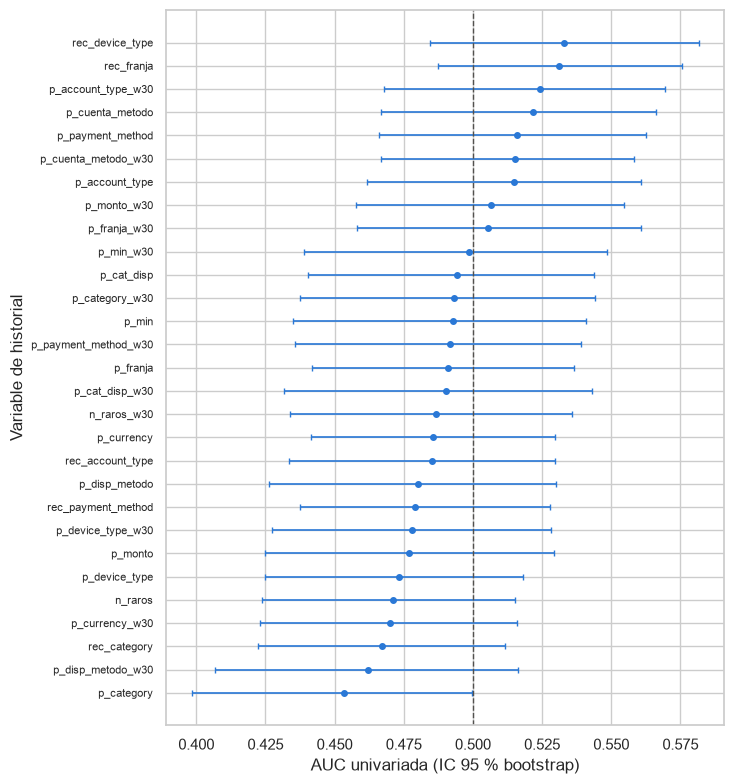

In [6]:
def bootstrap_ic(y_true, s, funcion, replicas=REPLICAS_BOOTSTRAP, semilla=RANDOM_STATE):
    rng = np.random.default_rng(semilla)
    pos, neg = np.flatnonzero(y_true == 1), np.flatnonzero(y_true == 0)
    valores = [funcion(y_true[i], s[i]) for i in
               (np.concatenate([rng.choice(pos, len(pos)), rng.choice(neg, len(neg))]) for _ in range(replicas))]
    return np.percentile(valores, [2.5, 97.5])


filas = []
for c in VARS_HIST:
    x = df[c].fillna(df[c].median()).to_numpy()
    if np.unique(x).size < 2:
        continue
    s = 1 - x if c.startswith("p_") else x
    lo, hi = bootstrap_ic(Y, s, roc_auc_score, replicas=500)
    filas.append({"variable": c, "AUC": roc_auc_score(Y, s), "inf": lo, "sup": hi,
                  "p": stats.mannwhitneyu(s[Y == 1], s[Y == 0]).pvalue})
auc_uni = pd.DataFrame(filas).set_index("variable")
auc_uni["q"] = stats.false_discovery_control(auc_uni["p"])
print(f"Variables con q < 0,05: {(auc_uni['q'] < 0.05).sum()} de {len(auc_uni)} · q mínimo = {auc_uni['q'].min():.3f}")
display(auc_uni.sort_values("AUC", ascending=False))

t = auc_uni.sort_values("AUC")
fig, ax = plt.subplots(figsize=(7.5, 8))
ax.errorbar(t["AUC"], range(len(t)), xerr=[t["AUC"] - t["inf"], t["sup"] - t["AUC"]], fmt="o", ms=4, lw=1.2,
            color=COLORES[0], capsize=2)
ax.axvline(0.5, color=COLOR_REF, ls="--", lw=1)
ax.set_yticks(range(len(t)), t.index, fontsize=8)
ax.set_xlabel("AUC univariada (IC 95 % bootstrap)")
ax.set_ylabel("Variable de historial")
savefig("fig_historial_auc_univariada")
plt.show()

*Figura (variables de historial). AUC univariada de cada variable de historial frente a `is_fraud`, con intervalo bootstrap al 95 %. Para las probabilidades se usa $1 - p$: una AUC mayor que 0,5 indicaría que los fraudes son más raros para su usuario. La línea discontinua es el azar.*

## 2. Conjuntos de variables (R5 y R8)

Ningún conjunto descarta variables: cada uno **añade** al anterior. Cada uno se evalúa **sin** y **con** `risk_score`.

| Conjunto | Contenido |
|---|---|
| **B0 base** | Variables originales y de caracterización del notebook 01 (el conjunto B del notebook 03) |
| **B1 +historial completo** | B0 + probabilidades 0–1 con toda la historia previa + recencia |
| **B2 +ventana 30 d** | B0 + probabilidades 0–1 con los últimos 30 días + recencia |
| **B3 +ambas** | B0 + historia completa + ventana de 30 días + recencia: **todas las variables** |

Cada uno tiene una versión «+ risk» con `risk_score`.

In [7]:
ORIGINALES_NUM = ["amount_log", "hour_sin", "hour_cos"]
ORIGINALES_BIN = ["is_weekend"]
CATEGORICAS = ["account_type", "category", "payment_method", "device_type"]
CARACT_CONT = [
    "transacciones_previas", "horas_desde_anterior_log", "desvio_log_monto",
    "transacciones_24h", "transacciones_7d", "monto_7d_log", "anomalia_historial",
]
CARACT_BIN = [
    "primera_transaccion", "cambio_dispositivo", "cambio_metodo_pago",
    "cambio_categoria", "dispositivo_nuevo", "cuenta_pago_incoherente",
]
BASE_CONT = ORIGINALES_NUM + CARACT_CONT
BASE_BIN = ORIGINALES_BIN + CARACT_BIN
SIN_RISK = {
    "B0 base": BASE_CONT,
    "B1 +historial completo": BASE_CONT + HIST_COMPLETO + REC,
    "B2 +ventana 30 d": BASE_CONT + HIST_W30 + REC,
    "B3 +ambas": BASE_CONT + HIST_COMPLETO + HIST_W30 + REC,
}
SETS = {}
for nombre, continuas in SIN_RISK.items():
    SETS[nombre] = dict(cont=continuas, bin=BASE_BIN)
    SETS[f"{nombre} + risk"] = dict(cont=continuas + ["risk_score"], bin=BASE_BIN)


def construir_preprocesador(spec):
    return ColumnTransformer([
        ("cont", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), spec["cont"]),
        ("bin", make_pipeline(SimpleImputer(strategy="constant", fill_value=0), StandardScaler()), spec["bin"]),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAS),
    ])


def columnas(spec):
    return spec["cont"] + spec["bin"] + CATEGORICAS


pd.DataFrame({
    nombre: {"variables de entrada": len(columnas(spec)),
             "columnas tras codificar": construir_preprocesador(spec).fit(df[columnas(spec)]).transform(df[columnas(spec)].head()).shape[1]}
    for nombre, spec in SETS.items()
}).T

,variables de entrada,columnas tras codificar
B0 base,21,36
B0 base + risk,22,37
B1 +historial completo,38,53
B1 +historial completo + risk,39,54
B2 +ventana 30 d,38,53
B2 +ventana 30 d + risk,39,54
B3 +ambas,50,65
B3 +ambas + risk,51,66


## 3. Protocolo temporal (R1 y R6)

Se evalúan los seis modelos del notebook 03 con las mismas mallas de hiperparámetros (el Random Forest balanceado usa 200 árboles por costo, como en el notebook 05). Los hiperparámetros se ajustan con **validación cruzada temporal expansiva**: el periodo de ajuste se divide en bloques cronológicos y en cada partición se entrena con los bloques 1 a k y se valida con el k + 1. **Nunca se mezclan pasado y futuro, y no se estratifica.**

- **Estrategia 1, partición única 80/20.** Ajuste con el 80 % más antiguo (6 bloques, 4 particiones de validación) y prueba con el 20 % más reciente.
- **Estrategia 2, *backtesting* mensual.** Los hiperparámetros se ajustan **solo con datos anteriores a febrero de 2026** (5 bloques, 3 particiones de validación). Luego, para cada mes de febrero a agosto, se reentrena con todo lo anterior y se predice el mes. Los puntajes de cada mes se convierten a rango percentil antes de juntarlos, porque cada reentrenamiento tiene su propia escala.

In [4]:
MODELOS = {
    "Regresión logística": dict(
        estimador=LogisticRegression(class_weight="balanced", max_iter=5000),
        malla={"modelo__C": [0.001, 0.01, 0.1, 1, 10]},
    ),
    "KNN": dict(
        estimador=KNeighborsClassifier(),
        submuestreo=True,
        malla={"modelo__n_neighbors": [15, 51, 151], "sub__sampling_strategy": [0.1, 0.5, 1.0]},
    ),
    "Random Forest balanceado": dict(
        estimador=BalancedRandomForestClassifier(
            n_estimators=N_ARBOLES, sampling_strategy="majority", replacement=False, bootstrap=False,
            random_state=RANDOM_STATE, n_jobs=1,
        ),
        malla={"modelo__min_samples_leaf": [1, 5, 20], "modelo__max_features": ["sqrt", 0.5]},
    ),
    "Gradient boosting": dict(
        estimador=HistGradientBoostingClassifier(
            max_iter=200, class_weight="balanced", early_stopping=False, random_state=RANDOM_STATE,
        ),
        malla={"modelo__learning_rate": [0.03, 0.1], "modelo__max_depth": [2, 4]},
    ),
    "Red neuronal (MLP)": dict(
        estimador=MLPClassifier(max_iter=300, random_state=RANDOM_STATE),
        pesos=True,
        malla={"modelo__hidden_layer_sizes": [(16,), (32, 16)], "modelo__alpha": [0.001, 0.1]},
    ),
    "SVM (RBF)": dict(
        estimador=SVC(kernel="rbf", class_weight="balanced"),
        malla={"modelo__C": [0.1, 1, 10], "modelo__gamma": ["scale", 0.01]},
    ),
}
NOMBRES_MODELOS = list(MODELOS)


def construir_pipeline(nombre_modelo, spec):
    m = MODELOS[nombre_modelo]
    pasos = [("pre", construir_preprocesador(spec))]
    if m.get("submuestreo"):
        return ImbPipeline(pasos + [("sub", RandomUnderSampler(random_state=RANDOM_STATE)), ("modelo", m["estimador"])])
    return Pipeline(pasos + [("modelo", m["estimador"])])


def argumentos_ajuste(nombre_modelo, y_tr):
    return {"modelo__sample_weight": compute_sample_weight("balanced", y_tr)} if MODELOS[nombre_modelo].get("pesos") else {}


def puntaje(modelo, X):
    if hasattr(modelo[-1], "decision_function"):
        return modelo.decision_function(X)
    return modelo.predict_proba(X)[:, 1]


def folds_expansivos(n, n_bloques, primer):
    bordes = np.linspace(0, n, n_bloques + 1).astype(int)
    return [(np.arange(bordes[k]), np.arange(bordes[k], bordes[k + 1])) for k in range(primer, n_bloques)]


def ajustar_hiperparametros(nombre_modelo, conjunto, idx, n_bloques, primer):
    spec = SETS[conjunto]
    busqueda = GridSearchCV(construir_pipeline(nombre_modelo, spec), MODELOS[nombre_modelo]["malla"],
                            scoring="average_precision", cv=folds_expansivos(len(idx), n_bloques, primer),
                            n_jobs=N_JOBS, refit=False)
    busqueda.fit(df.iloc[idx][columnas(spec)], Y[idx], **argumentos_ajuste(nombre_modelo, Y[idx]))
    resultados = pd.DataFrame(busqueda.cv_results_)
    mejor = int(np.nanargmax(resultados["mean_test_score"].to_numpy()))
    return resultados["params"].iloc[mejor], resultados["mean_test_score"].iloc[mejor]


def ajustar_y_puntuar(nombre_modelo, conjunto, idx_tr, idx_te, params, n_jobs=1):
    spec = SETS[conjunto]
    modelo = construir_pipeline(nombre_modelo, spec).set_params(**params)
    if nombre_modelo == "Random Forest balanceado":
        modelo.set_params(modelo__n_jobs=n_jobs)
    modelo.fit(df.iloc[idx_tr][columnas(spec)], Y[idx_tr], **argumentos_ajuste(nombre_modelo, Y[idx_tr]))
    return puntaje(modelo, df.iloc[idx_te][columnas(spec)])


FRACCIONES_ALERTA = {"1 %": 0.01, "2 %": 0.02}


def alertas_top(y_true, s, fraccion):
    k = int(np.ceil(fraccion * len(y_true)))
    return np.asarray(y_true)[np.argsort(-np.asarray(s), kind="stable")[:k]]


def metricas(y_true, s):
    salida = {"PR-AUC": average_precision_score(y_true, s), "ROC-AUC": roc_auc_score(y_true, s)}
    for etiqueta, f in FRACCIONES_ALERTA.items():
        top = alertas_top(y_true, s, f)
        salida[f"Precisión@{etiqueta}"] = top.mean()
        salida[f"Recall@{etiqueta}"] = top.sum() / np.sum(y_true)
    return salida


def auc_minima_detectable(n1, n0, alfa=0.05, potencia=0.8):
    se0 = np.sqrt((n1 + n0 + 1) / (12 * n1 * n0))
    return 0.5 + (stats.norm.ppf(1 - alfa / 2) + stats.norm.ppf(potencia)) * se0


def sin_prefijo(params):
    return {k.split("__")[1]: v for k, v in params.items()}

### 3.1 Tamaños y potencia

In [5]:
CORTE = int(0.8 * len(df))
IDX_TR, IDX_TE = np.arange(CORTE), np.arange(CORTE, len(df))
INICIO_BT = pd.Timestamp("2026-02-01")
IDX_PRE = np.flatnonzero((df["timestamp"] < INICIO_BT).to_numpy())
MESES = df["timestamp"].dt.to_period("M")
VENTANAS = [(str(mes), np.flatnonzero((MESES == mes).to_numpy())) for mes in sorted(MESES[df["timestamp"] >= INICIO_BT].unique())]
IDX_BT = np.concatenate([idx for _, idx in VENTANAS])
assert all((np.diff(idx) == 1).all() and idx[0] > 0 for _, idx in VENTANAS)

filas = [
    ("Estrategia 1: ajuste (80 % más antiguo)", IDX_TR, f"hasta {df['timestamp'].iloc[CORTE - 1]:%Y-%m-%d}"),
    ("Estrategia 1: prueba (20 % más reciente)", IDX_TE, f"desde {df['timestamp'].iloc[CORTE]:%Y-%m-%d}"),
    ("Estrategia 2: ajuste (antes de febrero de 2026)", IDX_PRE, "hasta 2026-01-31"),
    ("Estrategia 2: backtesting (febrero a agosto de 2026)", IDX_BT, f"{len(VENTANAS)} ventanas mensuales"),
]
tamanos = pd.DataFrame([{"conjunto": n, "transacciones": len(i), "fraudes": int(Y[i].sum()), "periodo": p,
                         "AUC mínima detectable": auc_minima_detectable(Y[i].sum(), (Y[i] == 0).sum())}
                        for n, i, p in filas]).set_index("conjunto")
display(tamanos)
print("Fraudes por ventana mensual:", {mes: int(Y[idx].sum()) for mes, idx in VENTANAS})
print("Fraudes en las particiones de validación temporal: estrategia 1",
      [int(Y[IDX_TR][va].sum()) for _, va in folds_expansivos(len(IDX_TR), 6, 2)],
      "| estrategia 2", [int(Y[IDX_PRE][va].sum()) for _, va in folds_expansivos(len(IDX_PRE), 5, 2)])

,transacciones,fraudes,periodo,AUC mínima detectable
conjunto,,,,
Estrategia 1: ajuste (80 % más antiguo),8000,102,hasta 2026-06-14,0.581
Estrategia 1: prueba (20 % más reciente),2000,24,desde 2026-06-14,0.666
Estrategia 2: ajuste (antes de febrero de 2026),4284,55,hasta 2026-01-31,0.610
Estrategia 2: backtesting (febrero a agosto de 2026),5716,71,7 ventanas mensuales,0.597


Fraudes por ventana mensual: {'2026-02': 8, '2026-03': 9, '2026-04': 11, '2026-05': 14, '2026-06': 12, '2026-07': 10, '2026-08': 7}
Fraudes en las particiones de validación temporal: estrategia 1 [21, 13, 15, 21] | estrategia 2 [14, 15, 11]


La AUC mínima detectable (potencia 0,8 y α = 0,05, con el error estándar de Hanley y McNeil bajo la hipótesis nula) muestra que la prueba de la estrategia 1 tiene pocos fraudes y **solo detectaría efectos grandes**. El *backtesting* junta más fraudes de prueba y por eso es la **estimación principal**.

### 3.2 Estrategia 1: partición única 80/20

In [10]:
mejores1, validacion1 = {}, {}
inicio = time.time()
for conjunto in SETS:
    for m in NOMBRES_MODELOS:
        mejores1[(conjunto, m)], validacion1[(conjunto, m)] = ajustar_hiperparametros(m, conjunto, IDX_TR, n_bloques=6, primer=2)
    print(f"{conjunto}: listo ({time.time() - inicio:.0f} s acumulados)")

B0 base: listo (27 s acumulados)
B0 base + risk: listo (48 s acumulados)
B1 +historial completo: listo (77 s acumulados)
B1 +historial completo + risk: listo (106 s acumulados)
B2 +ventana 30 d: listo (135 s acumulados)
B2 +ventana 30 d + risk: listo (165 s acumulados)
B3 +ambas: listo (212 s acumulados)
B3 +ambas + risk: listo (258 s acumulados)


In [11]:
filas = []
for (conjunto, m), params in mejores1.items():
    s = ajustar_y_puntuar(m, conjunto, IDX_TR, IDX_TE, params, n_jobs=N_JOBS)
    lo, hi = bootstrap_ic(Y[IDX_TE], s, average_precision_score)
    filas.append({"conjunto": conjunto, "modelo": m, **metricas(Y[IDX_TE], s), "inf": lo, "sup": hi,
                  "PR-AUC validación": validacion1[(conjunto, m)]})
res1 = pd.DataFrame(filas)

s_rs = df["risk_score"].to_numpy()[IDX_TE]
ref1 = {**metricas(Y[IDX_TE], s_rs)}
ref1["inf"], ref1["sup"] = bootstrap_ic(Y[IDX_TE], s_rs, average_precision_score)
AZAR1 = Y[IDX_TE].mean()
print(f"Azar (tasa de fraude en la prueba): PR-AUC = {AZAR1:.4f}")
print(f"risk_score sin modelo: PR-AUC = {ref1['PR-AUC']:.3f} [{ref1['inf']:.3f}, {ref1['sup']:.3f}] · "
      f"ROC-AUC = {ref1['ROC-AUC']:.3f} · Recall@2 % = {ref1['Recall@2 %']:.3f}")
print("\nPR-AUC en la prueba (estrategia 1)")
display(res1.pivot(index="modelo", columns="conjunto", values="PR-AUC").loc[NOMBRES_MODELOS][list(SETS)])
print("PR-AUC media de la validación temporal (mejor configuración)")
display(res1.pivot(index="modelo", columns="conjunto", values="PR-AUC validación").loc[NOMBRES_MODELOS][list(SETS)])
print("Hiperparámetros elegidos con todas las variables (B3 +ambas + risk)")
pd.Series({m: sin_prefijo(mejores1[("B3 +ambas + risk", m)]) for m in NOMBRES_MODELOS}).to_frame("hiperparámetros")

Azar (tasa de fraude en la prueba): PR-AUC = 0.0120
risk_score sin modelo: PR-AUC = 0.087 [0.021, 0.253] · ROC-AUC = 0.588 · Recall@2 % = 0.208

PR-AUC en la prueba (estrategia 1)


conjunto,B0 base,B0 base + risk,B1 +historial completo,B1 +historial completo + risk,B2 +ventana 30 d,B2 +ventana 30 d + risk,B3 +ambas,B3 +ambas + risk
modelo,,,,,,,,
Regresión logística,0.013,0.065,0.011,0.029,0.013,0.062,0.013,0.024
KNN,0.017,0.044,0.018,0.016,0.016,0.029,0.013,0.013
Random Forest balanceado,0.021,0.106,0.015,0.098,0.020,0.075,0.013,0.068
Gradient boosting,0.022,0.049,0.014,0.032,0.018,0.048,0.021,0.077
Red neuronal (MLP),0.012,0.019,0.010,0.031,0.014,0.061,0.013,0.022
SVM (RBF),0.016,0.029,0.014,0.020,0.018,0.030,0.016,0.023


PR-AUC media de la validación temporal (mejor configuración)


conjunto,B0 base,B0 base + risk,B1 +historial completo,B1 +historial completo + risk,B2 +ventana 30 d,B2 +ventana 30 d + risk,B3 +ambas,B3 +ambas + risk
modelo,,,,,,,,
Regresión logística,0.020,0.074,0.020,0.033,0.024,0.038,0.023,0.034
KNN,0.023,0.054,0.022,0.044,0.025,0.033,0.020,0.030
Random Forest balanceado,0.019,0.169,0.020,0.161,0.041,0.153,0.023,0.172
Gradient boosting,0.017,0.152,0.022,0.168,0.028,0.133,0.024,0.123
Red neuronal (MLP),0.018,0.021,0.020,0.038,0.018,0.033,0.019,0.021
SVM (RBF),0.019,0.064,0.031,0.049,0.034,0.055,0.028,0.058


Hiperparámetros elegidos con todas las variables (B3 +ambas + risk)


,hiperparámetros
Regresión logística,{'C': 0.001}
KNN,"{'n_neighbors': 51, 'sampling_strategy': 0.1}"
Random Forest balanceado,"{'max_features': 0.5, 'min_samples_leaf': 5}"
Gradient boosting,"{'learning_rate': 0.03, 'max_depth': 4}"
Red neuronal (MLP),"{'alpha': 0.001, 'hidden_layer_sizes': (32, 16)}"
SVM (RBF),"{'C': 0.1, 'gamma': 0.01}"


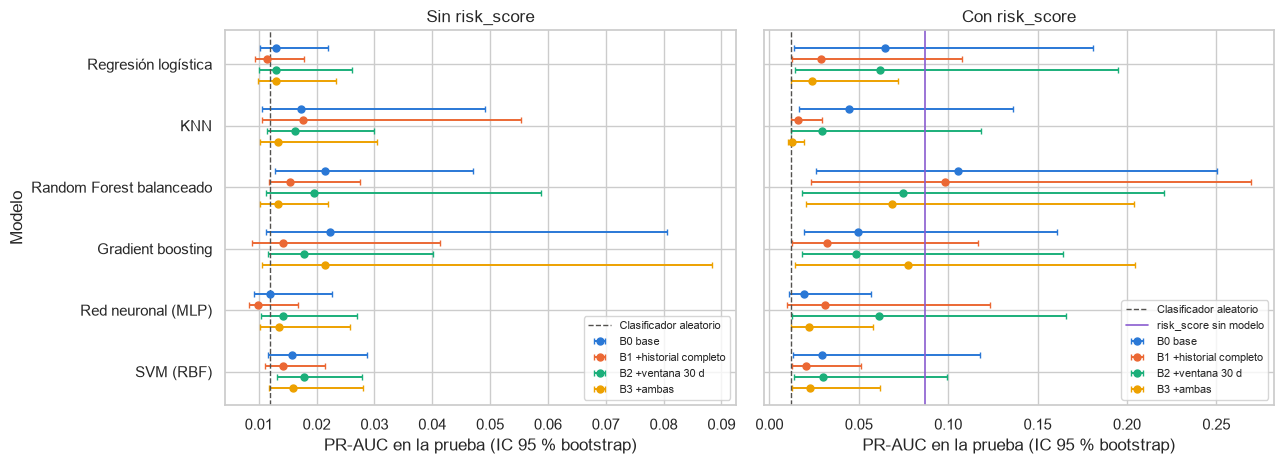

In [12]:
def figura_pr(res, azar, ref, nombre, titulo_eje):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
    for ax, con_risk in zip(axes, (False, True)):
        nombres = [n for n in SETS if n.endswith("+ risk") == con_risk]
        for j, (n, color) in enumerate(zip(nombres, COLORES)):
            t = res[res["conjunto"] == n].set_index("modelo").loc[NOMBRES_MODELOS]
            pos = np.arange(len(NOMBRES_MODELOS)) + (j - 1.5) * 0.18
            ax.errorbar(t["PR-AUC"], pos, xerr=[t["PR-AUC"] - t["inf"], t["sup"] - t["PR-AUC"]],
                        fmt="o", ms=5, lw=1.4, capsize=2, color=color, label=n.replace(" + risk", ""))
        ax.axvline(azar, color=COLOR_REF, ls="--", lw=1, label="Clasificador aleatorio")
        if con_risk:
            ax.axvline(ref, color=COLORES[4], lw=1.2, label="risk_score sin modelo")
        ax.set_yticks(range(len(NOMBRES_MODELOS)), NOMBRES_MODELOS)
        ax.set_title("Con risk_score" if con_risk else "Sin risk_score")
        ax.set_xlabel(titulo_eje)
        ax.legend(fontsize=8, loc="lower right")
    axes[0].set_ylabel("Modelo")
    axes[0].invert_yaxis()
    savefig(nombre)
    plt.show()


figura_pr(res1, AZAR1, ref1["PR-AUC"], "fig_temporal_particion_unica", "PR-AUC en la prueba (IC 95 % bootstrap)")

*Figura (partición temporal única). PR-AUC en el 20 % más reciente para los seis modelos y los cuatro conjuntos de variables, sin `risk_score` (izquierda) y con `risk_score` (derecha), con intervalos bootstrap estratificados al 95 %. La línea discontinua es un clasificador aleatorio y la continua, `risk_score` usado sin modelo.*

### 3.3 Estrategia 2: *backtesting* mensual

Hiperparámetros ajustados solo con datos anteriores a febrero de 2026; cada mes se predice con un modelo reentrenado con todo lo anterior.

In [13]:
mejores2, validacion2 = {}, {}
inicio = time.time()
for conjunto in SETS:
    for m in NOMBRES_MODELOS:
        mejores2[(conjunto, m)], validacion2[(conjunto, m)] = ajustar_hiperparametros(m, conjunto, IDX_PRE, n_bloques=5, primer=2)
    print(f"{conjunto}: listo ({time.time() - inicio:.0f} s acumulados)")

B0 base: listo (18 s acumulados)
B0 base + risk: listo (35 s acumulados)
B1 +historial completo: listo (57 s acumulados)
B1 +historial completo + risk: listo (80 s acumulados)
B2 +ventana 30 d: listo (102 s acumulados)
B2 +ventana 30 d + risk: listo (125 s acumulados)
B3 +ambas: listo (150 s acumulados)
B3 +ambas + risk: listo (177 s acumulados)


In [14]:
def rango_percentil(s):
    return stats.rankdata(s) / len(s)


def backtesting(nombre_modelo, conjunto, params):
    puntajes = Parallel(n_jobs=N_JOBS)(
        delayed(ajustar_y_puntuar)(nombre_modelo, conjunto, np.arange(idx[0]), idx, params) for _, idx in VENTANAS)
    return np.concatenate([rango_percentil(s) for s in puntajes])


pred2 = {}
inicio = time.time()
for (conjunto, m), params in mejores2.items():
    pred2[(conjunto, m)] = backtesting(m, conjunto, params)
    if m == NOMBRES_MODELOS[-1]:
        print(f"{conjunto}: listo ({time.time() - inicio:.0f} s acumulados)")

Y_BT = Y[IDX_BT]
AZAR2 = Y_BT.mean()
rs_bt = np.concatenate([rango_percentil(df["risk_score"].to_numpy()[idx]) for _, idx in VENTANAS])
filas = []
for (conjunto, m), s in pred2.items():
    lo, hi = bootstrap_ic(Y_BT, s, average_precision_score)
    filas.append({"conjunto": conjunto, "modelo": m, **metricas(Y_BT, s), "inf": lo, "sup": hi,
                  "PR-AUC validación": validacion2[(conjunto, m)]})
res2 = pd.DataFrame(filas)
ref2 = {**metricas(Y_BT, rs_bt)}
ref2["inf"], ref2["sup"] = bootstrap_ic(Y_BT, rs_bt, average_precision_score)
print(f"Azar (tasa de fraude en el backtesting): PR-AUC = {AZAR2:.4f}")
print(f"risk_score sin modelo: PR-AUC = {ref2['PR-AUC']:.3f} [{ref2['inf']:.3f}, {ref2['sup']:.3f}] · "
      f"ROC-AUC = {ref2['ROC-AUC']:.3f} · Recall@2 % = {ref2['Recall@2 %']:.3f}")
print("\nPR-AUC del backtesting (puntajes de las 7 ventanas agrupados)")
res2.pivot(index="modelo", columns="conjunto", values="PR-AUC").loc[NOMBRES_MODELOS][list(SETS)]

B0 base: listo (29 s acumulados)
B0 base + risk: listo (60 s acumulados)
B1 +historial completo: listo (101 s acumulados)
B1 +historial completo + risk: listo (140 s acumulados)
B2 +ventana 30 d: listo (178 s acumulados)
B2 +ventana 30 d + risk: listo (205 s acumulados)
B3 +ambas: listo (238 s acumulados)
B3 +ambas + risk: listo (273 s acumulados)
Azar (tasa de fraude en el backtesting): PR-AUC = 0.0124
risk_score sin modelo: PR-AUC = 0.159 [0.082, 0.270] · ROC-AUC = 0.624 · Recall@2 % = 0.254

PR-AUC del backtesting (puntajes de las 7 ventanas agrupados)


conjunto,B0 base,B0 base + risk,B1 +historial completo,B1 +historial completo + risk,B2 +ventana 30 d,B2 +ventana 30 d + risk,B3 +ambas,B3 +ambas + risk
modelo,,,,,,,,
Regresión logística,0.015,0.039,0.014,0.030,0.014,0.029,0.013,0.024
KNN,0.014,0.017,0.014,0.022,0.018,0.019,0.015,0.017
Random Forest balanceado,0.016,0.103,0.015,0.118,0.016,0.132,0.015,0.116
Gradient boosting,0.015,0.083,0.014,0.049,0.012,0.087,0.019,0.059
Red neuronal (MLP),0.012,0.015,0.011,0.017,0.013,0.019,0.013,0.019
SVM (RBF),0.013,0.020,0.015,0.025,0.016,0.020,0.015,0.025


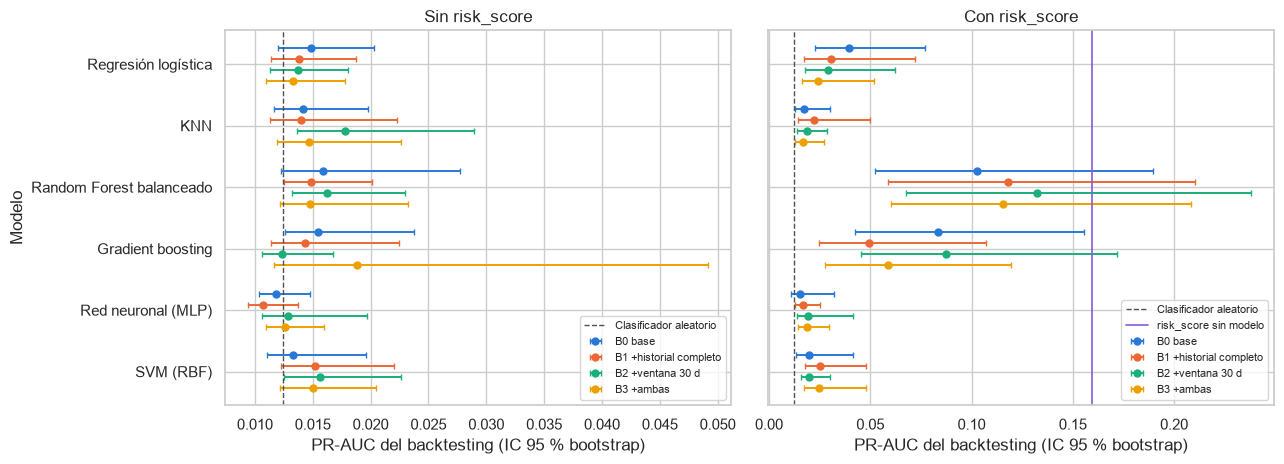

ROC-AUC del backtesting


conjunto,B0 base,B0 base + risk,B1 +historial completo,B1 +historial completo + risk,B2 +ventana 30 d,B2 +ventana 30 d + risk,B3 +ambas,B3 +ambas + risk
modelo,,,,,,,,
Regresión logística,0.531,0.636,0.524,0.620,0.523,0.628,0.506,0.610
KNN,0.524,0.534,0.511,0.578,0.567,0.586,0.530,0.567
Random Forest balanceado,0.541,0.643,0.571,0.653,0.572,0.662,0.547,0.648
Gradient boosting,0.549,0.620,0.505,0.583,0.501,0.630,0.498,0.627
Red neuronal (MLP),0.488,0.485,0.438,0.555,0.471,0.575,0.516,0.586
SVM (RBF),0.514,0.557,0.548,0.629,0.555,0.624,0.556,0.616


Recall@2 % del backtesting


conjunto,B0 base,B0 base + risk,B1 +historial completo,B1 +historial completo + risk,B2 +ventana 30 d,B2 +ventana 30 d + risk,B3 +ambas,B3 +ambas + risk
modelo,,,,,,,,
Regresión logística,0.000,0.141,0.014,0.070,0.000,0.085,0.000,0.042
KNN,0.014,0.056,0.028,0.056,0.070,0.056,0.042,0.042
Random Forest balanceado,0.042,0.254,0.014,0.254,0.014,0.254,0.028,0.254
Gradient boosting,0.028,0.211,0.028,0.155,0.014,0.225,0.042,0.169
Red neuronal (MLP),0.000,0.028,0.000,0.042,0.028,0.042,0.014,0.042
SVM (RBF),0.028,0.056,0.042,0.070,0.028,0.042,0.028,0.070


In [15]:
figura_pr(res2, AZAR2, ref2["PR-AUC"], "fig_temporal_backtesting", "PR-AUC del backtesting (IC 95 % bootstrap)")
print("ROC-AUC del backtesting")
display(res2.pivot(index="modelo", columns="conjunto", values="ROC-AUC").loc[NOMBRES_MODELOS][list(SETS)])
print("Recall@2 % del backtesting")
res2.pivot(index="modelo", columns="conjunto", values="Recall@2 %").loc[NOMBRES_MODELOS][list(SETS)]

*Figura (backtesting mensual). PR-AUC con los puntajes de las siete ventanas mensuales de febrero a agosto de 2026 agrupados (rango percentil dentro de cada ventana), para los seis modelos y los cuatro conjuntos de variables, con intervalos bootstrap estratificados al 95 %.*

### 3.4 ¿Historia completa o ventana de 30 días?

Promedio de los seis modelos para cada forma de construir el historial, sin y con `risk_score`. Si las probabilidades de historial aportaran señal, B1, B2 y B3 deberían superar a B0.

In [16]:
def resumen_conjuntos(res):
    return res.groupby("conjunto")[["PR-AUC", "ROC-AUC", "Recall@2 %"]].mean().loc[list(SETS)]


print("Estrategia 1 (prueba del 20 % más reciente): promedio de los 6 modelos")
display(resumen_conjuntos(res1))
print("Estrategia 2 (backtesting): promedio de los 6 modelos")
resumen_conjuntos(res2)

Estrategia 1 (prueba del 20 % más reciente): promedio de los 6 modelos


,PR-AUC,ROC-AUC,Recall@2 %
conjunto,,,
B0 base,0.017,0.516,0.028
B0 base + risk,0.052,0.597,0.125
B1 +historial completo,0.014,0.483,0.021
B1 +historial completo + risk,0.038,0.566,0.076
B2 +ventana 30 d,0.016,0.538,0.028
B2 +ventana 30 d + risk,0.051,0.581,0.111
B3 +ambas,0.015,0.509,0.014
B3 +ambas + risk,0.038,0.561,0.097


Estrategia 2 (backtesting): promedio de los 6 modelos


,PR-AUC,ROC-AUC,Recall@2 %
conjunto,,,
B0 base,0.014,0.525,0.019
B0 base + risk,0.046,0.579,0.124
B1 +historial completo,0.014,0.516,0.021
B1 +historial completo + risk,0.044,0.603,0.108
B2 +ventana 30 d,0.015,0.532,0.026
B2 +ventana 30 d + risk,0.051,0.618,0.117
B3 +ambas,0.015,0.526,0.026
B3 +ambas + risk,0.043,0.609,0.103


## 4. ¿La partición aleatoria y la temporal dan lo mismo?

El profesor pidió no usar particiones aleatorias, y los notebooks 03 a 05 las usan con el argumento de que los fraudes llegan sin tendencia ni rachas. Aquí se **comprueba**: con todas las variables (B3), sin y con `risk_score`, cada modelo se evalúa con los hiperparámetros de la estrategia 1 en las mismas 10 particiones aleatorias estratificadas de los notebooks 03 y 04 (5 particiones × 2 repeticiones, semilla `RANDOM_STATE + 1`), y se compara con las dos estrategias temporales. Las poblaciones de prueba no son idénticas, así que es una comparación de magnitud y no una prueba pareada.

In [17]:
CV_ALEATORIA = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=RANDOM_STATE + 1)
PARTICIONES = list(CV_ALEATORIA.split(df, Y))
R_NB = 1 / (5 - 1)


def ic_nb(v, r=R_NB, conf=0.95):
    v = np.asarray(v, dtype=float)
    h = stats.t.ppf((1 + conf) / 2, len(v) - 1) * np.sqrt(v.var(ddof=1) * (1 / len(v) + r))
    return v.mean(), v.mean() - h, v.mean() + h


def pr_auc_particion(nombre_modelo, conjunto, tr, te, params):
    return average_precision_score(Y[te], ajustar_y_puntuar(nombre_modelo, conjunto, tr, te, params))


filas = []
inicio = time.time()
for conjunto in ["B3 +ambas", "B3 +ambas + risk"]:
    for m in NOMBRES_MODELOS:
        valores = Parallel(n_jobs=N_JOBS)(delayed(pr_auc_particion)(m, conjunto, tr, te, mejores1[(conjunto, m)])
                                          for tr, te in PARTICIONES)
        media, lo, hi = ic_nb(valores)
        r1 = res1[(res1["conjunto"] == conjunto) & (res1["modelo"] == m)].iloc[0]
        r2 = res2[(res2["conjunto"] == conjunto) & (res2["modelo"] == m)].iloc[0]
        filas.append({"conjunto": conjunto, "modelo": m,
                      "aleatoria (10 particiones)": f"{media:.3f} [{lo:.3f}, {hi:.3f}]",
                      "temporal 80/20": f"{r1['PR-AUC']:.3f} [{r1['inf']:.3f}, {r1['sup']:.3f}]",
                      "backtesting": f"{r2['PR-AUC']:.3f} [{r2['inf']:.3f}, {r2['sup']:.3f}]"})
    print(f"{conjunto}: listo ({time.time() - inicio:.0f} s acumulados)")
print(f"Azar: {Y.mean():.4f} (base completa) · {AZAR1:.4f} (prueba del 20 %) · {AZAR2:.4f} (backtesting)")
pd.DataFrame(filas).set_index(["conjunto", "modelo"])

B3 +ambas: listo (51 s acumulados)
B3 +ambas + risk: listo (109 s acumulados)
Azar: 0.0126 (base completa) · 0.0120 (prueba del 20 %) · 0.0124 (backtesting)


aleatoria (10 particiones)        temporal 80/20           backtesting
conjunto         modelo                                                                                         
B3 +ambas        Regresión logística            0.019 [0.001, 0.037]  0.013 [0.010, 0.023]  0.013 [0.011, 0.018]
                 KNN                            0.016 [0.010, 0.023]  0.013 [0.010, 0.030]  0.015 [0.012, 0.023]
                 Random Forest balanceado       0.017 [0.011, 0.023]  0.013 [0.010, 0.022]  0.015 [0.012, 0.023]
                 Gradient boosting              0.016 [0.012, 0.020]  0.021 [0.011, 0.088]  0.019 [0.012, 0.049]
                 Red neuronal (MLP)             0.021 [0.002, 0.039]  0.013 [0.010, 0.026]  0.013 [0.011, 0.016]
                 SVM (RBF)                     0.025 [-0.005, 0.055]  0.016 [0.012, 0.028]  0.015 [0.012, 0.020]
B3 +ambas + risk Regresión logística            0.035 [0.012, 0.058]  0.024 [0.012, 0.072]  0.024 [0.016, 0.052]
                 KNN                            0.023 [0.005, 0.041]  0.013 [0.010, 0.019]  0.017 [0.013, 0.027]
                 Random Forest balanceado       0.125 [0.035, 0.216]  0.068 [0.020, 0.204]  0.116 [0.060, 0.208]
                 Gradient boosting              0.108 [0.027, 0.189]  0.077 [0.014, 0.205]  0.059 [0.028, 0.120]
                 Red neuronal (MLP)             0.026 [0.016, 0.036]  0.022 [0.012, 0.058]  0.019 [0.014, 0.029]
                 SVM (RBF)                      0.043 [0.011, 0.075]  0.023 [0.013, 0.062]  0.025 [0.017, 0.048]

## 5. Detección de anomalías sobre las probabilidades de historial (R7)

Se entrenan **Isolation Forest** y **One-Class SVM** (`nu` = 0,01 y 0,05, con una submuestra de 3.000 normales por costo, como en el notebook 04) solo con transacciones **normales** del periodo de entrenamiento. Cada transacción posterior es más sospechosa cuanto más atípicas sean sus probabilidades de historial: es la idea del profesor de que una transacción es anómala si sus atributos son raros *para ese usuario*. Espacios:

- **P completo:** las probabilidades con toda la historia previa (incluye `p_currency`, prácticamente constante).
- **P ventana 30 d:** las mismas con los últimos 30 días.
- **P completo + risk_score.**
- **Solo risk_score** (referencia).

Se aplica con las dos estrategias temporales.

In [18]:
ESPACIOS = {"P completo": P_COMPLETO, "P ventana 30 d": P_W30,
            "P completo + risk_score": P_COMPLETO + ["risk_score"], "Solo risk_score": ["risk_score"]}


def puntajes_anomalia(X_tr, X_te, semilla=RANDOM_STATE):
    escala = StandardScaler().fit(X_tr)
    Zn, Zt = escala.transform(X_tr), escala.transform(X_te)
    salida = {"Isolation Forest": -IsolationForest(n_estimators=200, random_state=RANDOM_STATE).fit(Zn).score_samples(Zt)}
    sub = np.random.default_rng(semilla).choice(len(Zn), min(3000, len(Zn)), replace=False)
    for nu in (0.01, 0.05):
        salida[f"One-Class SVM (nu = {nu})"] = -OneClassSVM(nu=nu, gamma="scale").fit(Zn[sub]).score_samples(Zt)
    return salida


def anomalia_ventana(X, idx):
    tr = np.arange(idx[0])
    return puntajes_anomalia(X[tr[Y[tr] == 0]], X[idx])


filas1, filas2 = [], []
inicio = time.time()
for espacio, cols_e in ESPACIOS.items():
    X = df[cols_e].to_numpy(dtype=float)
    normales = IDX_TR[Y[IDX_TR] == 0]
    for detector, s in puntajes_anomalia(X[normales], X[IDX_TE]).items():
        lo, hi = bootstrap_ic(Y[IDX_TE], s, average_precision_score)
        filas1.append({"espacio": espacio, "detector": detector, **metricas(Y[IDX_TE], s), "inf": lo, "sup": hi})
    por_ventana = Parallel(n_jobs=N_JOBS)(delayed(anomalia_ventana)(X, idx) for _, idx in VENTANAS)
    for detector in por_ventana[0]:
        s = np.concatenate([rango_percentil(v[detector]) for v in por_ventana])
        lo, hi = bootstrap_ic(Y_BT, s, average_precision_score)
        filas2.append({"espacio": espacio, "detector": detector, **metricas(Y_BT, s), "inf": lo, "sup": hi})
    print(f"{espacio}: listo ({time.time() - inicio:.0f} s acumulados)")
anom1, anom2 = pd.DataFrame(filas1), pd.DataFrame(filas2)
DETECTORES = list(anom1["detector"].unique())

print(f"Azar: {AZAR1:.4f} (estrategia 1) · {AZAR2:.4f} (estrategia 2)")
for nombre, t in [("Estrategia 1 (partición 80/20)", anom1), ("Estrategia 2 (backtesting)", anom2)]:
    print(f"{nombre}: PR-AUC")
    display(t.pivot(index="detector", columns="espacio", values="PR-AUC")[list(ESPACIOS)])
    print(f"{nombre}: ROC-AUC")
    display(t.pivot(index="detector", columns="espacio", values="ROC-AUC")[list(ESPACIOS)])

P completo: listo (17 s acumulados)
P ventana 30 d: listo (33 s acumulados)
P completo + risk_score: listo (50 s acumulados)
Solo risk_score: listo (66 s acumulados)
Azar: 0.0120 (estrategia 1) · 0.0124 (estrategia 2)
Estrategia 1 (partición 80/20): PR-AUC


espacio,P completo,P ventana 30 d,P completo + risk_score,Solo risk_score
detector,,,,
Isolation Forest,0.048,0.013,0.055,0.076
One-Class SVM (nu = 0.01),0.025,0.012,0.025,0.017
One-Class SVM (nu = 0.05),0.028,0.012,0.032,0.071


Estrategia 1 (partición 80/20): ROC-AUC


espacio,P completo,P ventana 30 d,P completo + risk_score,Solo risk_score
detector,,,,
Isolation Forest,0.525,0.497,0.583,0.576
One-Class SVM (nu = 0.01),0.552,0.466,0.619,0.500
One-Class SVM (nu = 0.05),0.550,0.465,0.631,0.586


Estrategia 2 (backtesting): PR-AUC


espacio,P completo,P ventana 30 d,P completo + risk_score,Solo risk_score
detector,,,,
Isolation Forest,0.018,0.014,0.021,0.157
One-Class SVM (nu = 0.01),0.018,0.016,0.030,0.030
One-Class SVM (nu = 0.05),0.017,0.015,0.032,0.151


Estrategia 2 (backtesting): ROC-AUC


espacio,P completo,P ventana 30 d,P completo + risk_score,Solo risk_score
detector,,,,
Isolation Forest,0.507,0.532,0.565,0.635
One-Class SVM (nu = 0.01),0.520,0.522,0.613,0.501
One-Class SVM (nu = 0.05),0.514,0.520,0.616,0.629


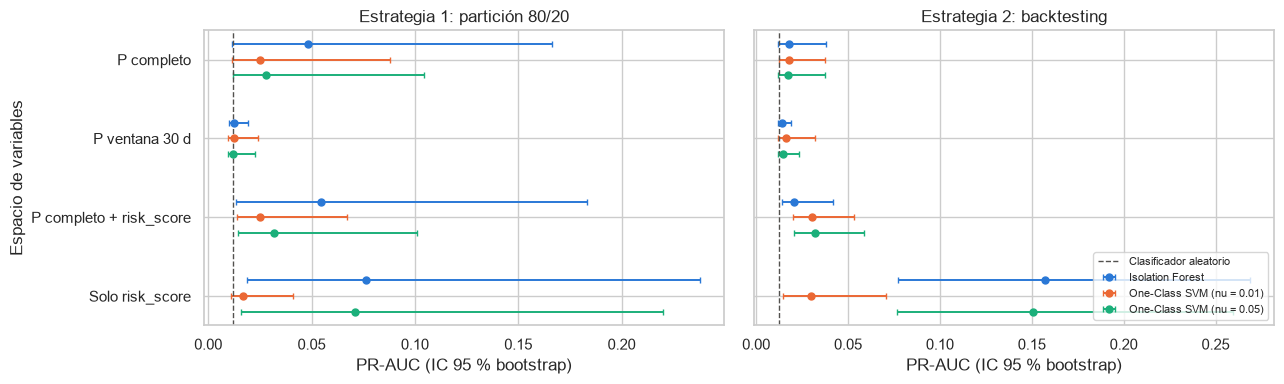

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, (titulo, t, azar) in zip(axes, [("Estrategia 1: partición 80/20", anom1, AZAR1), ("Estrategia 2: backtesting", anom2, AZAR2)]):
    for j, (detector, color) in enumerate(zip(DETECTORES, COLORES)):
        u = t[t["detector"] == detector].set_index("espacio").loc[list(ESPACIOS)]
        pos = np.arange(len(ESPACIOS)) + (j - 1) * 0.2
        ax.errorbar(u["PR-AUC"], pos, xerr=[u["PR-AUC"] - u["inf"], u["sup"] - u["PR-AUC"]], fmt="o", ms=5, lw=1.4,
                    capsize=2, color=color, label=detector)
    ax.axvline(azar, color=COLOR_REF, ls="--", lw=1, label="Clasificador aleatorio")
    ax.set_yticks(range(len(ESPACIOS)), list(ESPACIOS))
    ax.set_title(titulo)
    ax.set_xlabel("PR-AUC (IC 95 % bootstrap)")
axes[0].set_ylabel("Espacio de variables")
axes[0].invert_yaxis()
axes[1].legend(fontsize=8, loc="lower right")
savefig("fig_temporal_anomalias")
plt.show()

*Figura (anomalías sobre el historial). Detectores de una clase entrenados solo con transacciones normales, sobre las probabilidades de historial, con la partición temporal 80/20 (izquierda) y el backtesting mensual (derecha). Intervalos bootstrap estratificados al 95 %; la línea discontinua es un clasificador aleatorio.*

## 6. Control positivo: ¿el método detectaría una moneda nueva? (R3)

Como la base solo tiene USD, se **simula** la anomalía: en el 20 % más reciente se eligen al azar 100 transacciones de usuarios con al menos 3 transacciones previas y se les cambia la moneda a «SOL». Se recalculan las probabilidades de historial con el mismo procedimiento causal y se mide si `p_currency` y los detectores, entrenados con las normales del 80 % más antiguo (que no se modifica), separan las transacciones inyectadas del resto. Se repite multiplicando el **monto por 15**.

Son anomalías sintéticas: muestran que el método **puede** detectar ese tipo de anomalía, no que ocurra en los datos. Un punto a verificar: en el periodo de entrenamiento `p_currency` es prácticamente constante, así que no es obvio que los detectores aprovechen esa columna; el control lo comprueba.

In [20]:
def control_positivo(tipo, k=100, semilla=RANDOM_STATE):
    rng = np.random.default_rng(semilla)
    simulada = base.copy()
    elegibles = IDX_TE[simulada["transacciones_previas"].to_numpy()[IDX_TE] >= 3]
    inyectadas = rng.choice(elegibles, size=k, replace=False)
    if tipo == "moneda nueva (SOL)":
        simulada.loc[inyectadas, "currency"] = "SOL"
        columna = "p_currency"
    else:
        simulada.loc[inyectadas, "amount"] = simulada.loc[inyectadas, "amount"] * 15
        simulada["amount_log"] = np.log1p(simulada["amount"])
        columna = "p_monto"
    hist = construir_historial(simulada)
    marca = np.zeros(len(simulada), dtype=int)
    marca[inyectadas] = 1
    X = hist[P_COMPLETO].to_numpy(dtype=float)
    normales = IDX_TR[Y[IDX_TR] == 0]
    fila = {"anomalía simulada": tipo, "transacciones inyectadas": k,
            "AUC de 1 − p (la propia variable)": roc_auc_score(marca[IDX_TE], 1 - hist[columna].to_numpy()[IDX_TE])}
    for detector, s in puntajes_anomalia(X[normales], X[IDX_TE]).items():
        fila[f"AUC {detector}"] = roc_auc_score(marca[IDX_TE], s)
    fila["mediana de p (inyectadas)"] = np.median(hist[columna].to_numpy()[inyectadas])
    fila["mediana de p (resto de la prueba)"] = np.median(hist[columna].to_numpy()[np.setdiff1d(IDX_TE, inyectadas)])
    return fila


pd.DataFrame([control_positivo("moneda nueva (SOL)"), control_positivo("monto × 15")]).set_index("anomalía simulada").T

anomalía simulada,moneda nueva (SOL),monto × 15
transacciones inyectadas,100.000,100.000
AUC de 1 − p (la propia variable),1.000,0.893
AUC Isolation Forest,0.980,0.605
AUC One-Class SVM (nu = 0.01),1.000,0.645
AUC One-Class SVM (nu = 0.05),1.000,0.625
mediana de p (inyectadas),0.001,0.005
mediana de p (resto de la prueba),0.998,0.424


## 7. Modelo final con todas las variables (R5)

El modelo final **recibe todas las variables** (conjunto B3). Se reportan las dos versiones, sin y con `risk_score`, y se comparan con `risk_score` usado directamente. Entre los seis modelos se elige el de mayor PR-AUC en la **validación temporal** de la estrategia 2 (no en el backtesting), para no elegir con los datos de evaluación.

In [21]:
def mejor_por_validacion(conjunto):
    v = {m: validacion2[(conjunto, m)] for m in NOMBRES_MODELOS}
    return max(v, key=v.get), v


filas = []
for conjunto in ["B3 +ambas", "B3 +ambas + risk"]:
    elegido, v = mejor_por_validacion(conjunto)
    r = res2[(res2["conjunto"] == conjunto) & (res2["modelo"] == elegido)].iloc[0]
    filas.append({"conjunto": conjunto, "modelo elegido": elegido, "hiperparámetros": sin_prefijo(mejores2[(conjunto, elegido)]),
                  "PR-AUC validación": v[elegido], "PR-AUC backtesting [IC 95 %]": f"{r['PR-AUC']:.3f} [{r['inf']:.3f}, {r['sup']:.3f}]",
                  **{k: r[k] for k in ["ROC-AUC", "Precisión@1 %", "Recall@1 %", "Precisión@2 %", "Recall@2 %"]}})
filas.append({"conjunto": "risk_score sin modelo", "modelo elegido": "—",
              "PR-AUC backtesting [IC 95 %]": f"{ref2['PR-AUC']:.3f} [{ref2['inf']:.3f}, {ref2['sup']:.3f}]",
              **{k: ref2[k] for k in ["ROC-AUC", "Precisión@1 %", "Recall@1 %", "Precisión@2 %", "Recall@2 %"]}})
filas.append({"conjunto": "Clasificador aleatorio", "modelo elegido": "—", "PR-AUC backtesting [IC 95 %]": f"{AZAR2:.3f}",
              "ROC-AUC": 0.5, "Precisión@1 %": AZAR2, "Recall@1 %": 0.01, "Precisión@2 %": AZAR2, "Recall@2 %": 0.02})
modelo_final = pd.DataFrame(filas).set_index("conjunto").fillna("")
modelo_final

,modelo elegido,hiperparámetros,PR-AUC validación,PR-AUC backtesting [IC 95 %],ROC-AUC,Precisión@1 %,Recall@1 %,Precisión@2 %,Recall@2 %
conjunto,,,,,,,,,
B3 +ambas,Red neuronal (MLP),"{'alpha': 0.001, 'hidden_layer_sizes': (32, 16)}",0.050,"0.013 [0.011, 0.016]",0.516,0.000,0.000,0.009,0.014
B3 +ambas + risk,SVM (RBF),"{'C': 0.1, 'gamma': 0.01}",0.054,"0.025 [0.017, 0.048]",0.616,0.034,0.028,0.043,0.070
risk_score sin modelo,—,,,"0.159 [0.082, 0.270]",0.624,0.310,0.254,0.157,0.254
Clasificador aleatorio,—,,,0.012,0.500,0.012,0.010,0.012,0.020


### ¿Por qué la validación de la estrategia 2 elige otro modelo?

La estrategia 2 elige los hiperparámetros y el modelo con solo 55 fraudes anteriores a febrero de 2026. Si alguna partición de validación tiene pocos fraudes con `risk_score` alto, que son los únicos detectables, la PR-AUC de validación de los modelos que dependen de `risk_score` se desploma y la selección queda a merced del ruido. La tabla siguiente lo revisa en las particiones de validación de ambas estrategias, con la PR-AUC de `risk_score` usado sin modelo como referencia de cuánta señal hay en cada una.

In [6]:
riesgo = df["risk_score"].to_numpy()
filas = []
for nombre, idx, n_bloques in [("Estrategia 1", IDX_TR, 6), ("Estrategia 2", IDX_PRE, 5)]:
    for k, (_, va) in enumerate(folds_expansivos(len(idx), n_bloques, 2), start=1):
        v = idx[va]
        filas.append({"estrategia": nombre, "partición de validación": k,
                      "periodo": f"{df['timestamp'].iloc[v[0]]:%Y-%m-%d} a {df['timestamp'].iloc[v[-1]]:%Y-%m-%d}",
                      "fraudes": int(Y[v].sum()), "fraudes con risk_score ≥ 70": int(((Y[v] == 1) & (riesgo[v] >= 70)).sum()),
                      "PR-AUC de risk_score": average_precision_score(Y[v], riesgo[v])})
pd.DataFrame(filas).set_index(["estrategia", "partición de validación"])

periodo  fraudes  fraudes con risk_score ≥ 70  PR-AUC de risk_score
estrategia   partición de validación                                                                                     
Estrategia 1 1                        2025-12-03 a 2026-01-21       21                            4                 0.167
             2                        2026-01-21 a 2026-03-09       13                            3                 0.095
             3                        2026-03-09 a 2026-04-25       15                            3                 0.143
             4                        2026-04-25 a 2026-06-14       21                            8                 0.377
Estrategia 2 1                        2025-10-29 a 2025-11-30       14                            3                 0.083
             2                        2025-11-30 a 2025-12-30       15                            4                 0.249
             3                        2025-12-30 a 2026-01-31       11                            0                 0.013

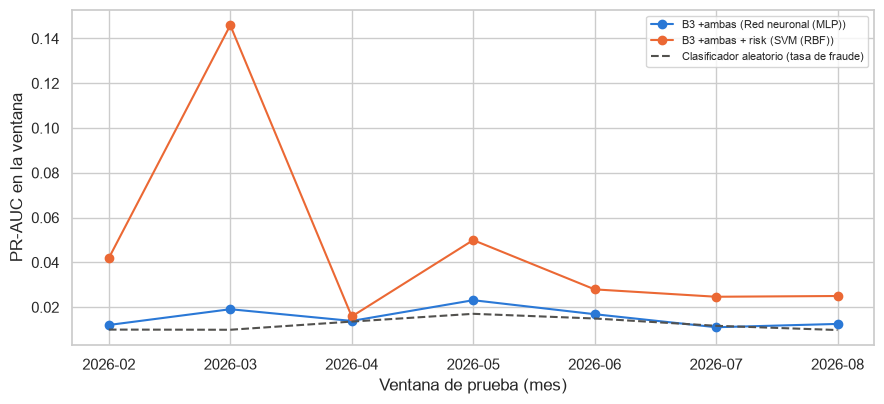

modelo  transacciones  fraudes  PR-AUC  ROC-AUC  azar
conjunto         ventana                                                                   
B3 +ambas        2026-02  Red neuronal (MLP)            801        8   0.012    0.535 0.010
                 2026-03  Red neuronal (MLP)            908        9   0.019    0.646 0.010
                 2026-04  Red neuronal (MLP)            811       11   0.014    0.476 0.014
                 2026-05  Red neuronal (MLP)            822       14   0.023    0.487 0.017
                 2026-06  Red neuronal (MLP)            803       12   0.017    0.522 0.015
                 2026-07  Red neuronal (MLP)            856       10   0.011    0.445 0.012
                 2026-08  Red neuronal (MLP)            715        7   0.013    0.537 0.010
B3 +ambas + risk 2026-02           SVM (RBF)            801        8   0.042    0.670 0.010
                 2026-03           SVM (RBF)            908        9   0.146    0.668 0.010
                 2026-04           SVM (RBF)            811       11   0.016    0.480 0.014
                 2026-05           SVM (RBF)            822       14   0.050    0.693 0.017
                 2026-06           SVM (RBF)            803       12   0.028    0.658 0.015
                 2026-07           SVM (RBF)            856       10   0.025    0.504 0.012
                 2026-08           SVM (RBF)            715        7   0.025    0.636 0.010

In [22]:
filas = []
for conjunto in ["B3 +ambas", "B3 +ambas + risk"]:
    elegido, _ = mejor_por_validacion(conjunto)
    s_total = pred2[(conjunto, elegido)]
    pos = 0
    for mes, idx in VENTANAS:
        s = s_total[pos:pos + len(idx)]
        pos += len(idx)
        filas.append({"conjunto": conjunto, "modelo": elegido, "ventana": mes, "transacciones": len(idx),
                      "fraudes": int(Y[idx].sum()), "PR-AUC": average_precision_score(Y[idx], s),
                      "ROC-AUC": roc_auc_score(Y[idx], s), "azar": Y[idx].mean()})
por_ventana = pd.DataFrame(filas)

fig, ax = plt.subplots(figsize=(9, 4.2))
for conjunto, color in zip(["B3 +ambas", "B3 +ambas + risk"], COLORES[:2]):
    t = por_ventana[por_ventana["conjunto"] == conjunto]
    ax.plot(t["ventana"], t["PR-AUC"], "-o", color=color, label=f"{conjunto} ({t['modelo'].iloc[0]})")
t = por_ventana[por_ventana["conjunto"] == "B3 +ambas"]
ax.plot(t["ventana"], t["azar"], "--", color=COLOR_REF, label="Clasificador aleatorio (tasa de fraude)")
ax.set_xlabel("Ventana de prueba (mes)")
ax.set_ylabel("PR-AUC en la ventana")
ax.legend(fontsize=8)
savefig("fig_temporal_por_ventana")
plt.show()
por_ventana.set_index(["conjunto", "ventana"])

*Figura (desempeño por mes). PR-AUC de cada ventana mensual del backtesting para el modelo final con todas las variables, sin y con `risk_score`. La línea discontinua es la tasa de fraude de cada mes (clasificador aleatorio). Con unos 10 fraudes por ventana, cada punto es muy ruidoso.*

## 8. Conclusiones

Resumen automático de las cifras principales, generado a partir de las tablas anteriores para que el texto no pueda contradecir los resultados:

In [23]:
def resumen_estrategia(res, azar, ref, etiqueta):
    print(f"[{etiqueta}] azar = {azar:.3f} · risk_score sin modelo = {ref['PR-AUC']:.3f} [{ref['inf']:.3f}, {ref['sup']:.3f}]")
    for nombre, con_risk in (("Sin risk_score", False), ("Con risk_score", True)):
        r = res[res["conjunto"].str.endswith("+ risk") == con_risk].sort_values("PR-AUC", ascending=False).iloc[0]
        lectura = "el IC excluye el azar" if r["inf"] > azar else "el IC incluye el azar"
        print(f"   {nombre}: mejor = {r['modelo']} / {r['conjunto']}: PR-AUC {r['PR-AUC']:.3f} [{r['inf']:.3f}, {r['sup']:.3f}] ({lectura})")
    promedio = res.assign(con_risk=res["conjunto"].str.endswith("+ risk")).groupby("con_risk")["PR-AUC"].mean()
    print(f"   Promedio de los 6 modelos y 4 conjuntos: sin risk_score {promedio[False]:.3f} · con risk_score {promedio[True]:.3f}")


resumen_estrategia(res1, AZAR1, ref1, "Estrategia 1: partición 80/20")
resumen_estrategia(res2, AZAR2, ref2, "Estrategia 2: backtesting")
for nombre, t, azar in (("Estrategia 1", anom1, AZAR1), ("Estrategia 2", anom2, AZAR2)):
    r = t[t["espacio"].isin(["P completo", "P ventana 30 d"])].sort_values("PR-AUC", ascending=False).iloc[0]
    print(f"Anomalías sobre las probabilidades ({nombre}): mejor = {r['detector']} / {r['espacio']}: "
          f"PR-AUC {r['PR-AUC']:.3f} [{r['inf']:.3f}, {r['sup']:.3f}] frente a {azar:.3f} del azar")
print(f"Variables de historial con q < 0,05 (análisis individual): {(auc_uni['q'] < 0.05).sum()} de {len(auc_uni)}")

[Estrategia 1: partición 80/20] azar = 0.012 · risk_score sin modelo = 0.087 [0.021, 0.253]
   Sin risk_score: mejor = Gradient boosting / B0 base: PR-AUC 0.022 [0.011, 0.081] (el IC incluye el azar)
   Con risk_score: mejor = Random Forest balanceado / B0 base + risk: PR-AUC 0.106 [0.026, 0.250] (el IC excluye el azar)
   Promedio de los 6 modelos y 4 conjuntos: sin risk_score 0.016 · con risk_score 0.045
[Estrategia 2: backtesting] azar = 0.012 · risk_score sin modelo = 0.159 [0.082, 0.270]
   Sin risk_score: mejor = Gradient boosting / B3 +ambas: PR-AUC 0.019 [0.012, 0.049] (el IC incluye el azar)
   Con risk_score: mejor = Random Forest balanceado / B2 +ventana 30 d + risk: PR-AUC 0.132 [0.068, 0.238] (el IC excluye el azar)
   Promedio de los 6 modelos y 4 conjuntos: sin risk_score 0.014 · con risk_score 0.046
Anomalías sobre las probabilidades (Estrategia 1): mejor = Isolation Forest / P completo: PR-AUC 0.048 [0.012, 0.166] frente a 0.012 del azar
Anomalías sobre las probabilida

**1. Las probabilidades de historial no tienen señal (R2 y R4).** Las 29 variables nuevas (probabilidades 0–1 de cada atributo y de sus combinaciones, probabilidad del monto, resúmenes y recencia, con toda la historia y con la ventana de 30 días) se calculan solo con el pasado: al truncar el futuro, la diferencia máxima es de 2,6 × 10⁻¹⁵, un error de redondeo. Ninguna tiene señal individual: AUC entre 0,45 y 0,53 y q > 0,86 en todas (0 de 29 con q < 0,05). Las de mayor AUC son dos recencias (0,53), y la menor, `p_category` (0,45), va en contra de la hipótesis: si acaso, los fraudes ocurren en categorías **habituales** para el usuario. Los fraudes no son más raros para su usuario que las transacciones normales, lo que confirma con las variables que pidió el profesor lo que el notebook 01 había encontrado con `anomalia_historial`.

**2. Con el protocolo temporal, el resultado no cambia (R1 y R6).** Ningún modelo supera al azar sin `risk_score`, y ninguno supera a `risk_score` usado sin modelo cuando lo incluye:

| Estrategia | Azar | Mejor sin `risk_score` | Mejor con `risk_score` | `risk_score` sin modelo |
|---|---|---|---|---|
| Partición 80/20 (24 fraudes de prueba) | 0,012 | 0,022 [0,011; 0,081] (gradient boosting, B0) | 0,106 [0,026; 0,250] (Random Forest balanceado, B0) | 0,087 [0,021; 0,253] |
| *Backtesting* mensual (71 fraudes de prueba) | 0,012 | 0,019 [0,012; 0,049] (gradient boosting, B3) | 0,132 [0,068; 0,238] (Random Forest balanceado, B2) | 0,159 [0,082; 0,270] |

En el *backtesting*, que es la estimación principal, el promedio de los seis modelos sin `risk_score` es 0,014, prácticamente el azar. Con `risk_score`, el Random Forest balanceado es el mejor modelo en los cuatro conjuntos (de 0,103 a 0,132), seguido del gradient boosting (de 0,049 a 0,087), mientras que la regresión logística, KNN, la red neuronal y la SVM quedan por debajo de 0,04. Es la misma jerarquía de los notebooks 03 y 04: los árboles capturan el escalón de `risk_score` en torno a 70 y los demás modelos lo diluyen. El recall al revisar el 2 % del Random Forest (0,254) es igual al de `risk_score` sin modelo (0,254).

**3. Ni la historia completa ni la ventana de 30 días ayudan.** En el *backtesting*, el promedio de los seis modelos sin `risk_score` es 0,014 (B0), 0,014 (B1), 0,015 (B2) y 0,015 (B3); con `risk_score`, 0,046, 0,044, 0,051 y 0,043. En la partición 80/20, agregar las probabilidades de historial incluso baja el promedio con `risk_score` (de 0,052 en B0 a 0,038 en B1 y B3), porque los modelos sensibles al ruido pierden la señal entre más columnas sin información. La ventana de 30 días queda ligeramente por encima de la historia completa, pero las diferencias son mucho menores que los intervalos.

**4. La partición aleatoria y la temporal dan lo mismo.** Con todas las variables (B3), sin `risk_score` los seis modelos quedan entre 0,016 y 0,025 con la partición aleatoria, entre 0,013 y 0,021 con la temporal 80/20 y entre 0,013 y 0,019 con el *backtesting*: azar en los tres esquemas. Con `risk_score`, el Random Forest balanceado obtiene 0,125 [0,035; 0,216] con la aleatoria, 0,068 [0,020; 0,204] con la 80/20 y 0,116 [0,060; 0,208] con el *backtesting*, y el gradient boosting 0,108, 0,077 y 0,059, con intervalos que se solapan ampliamente. La partición 80/20 sale más baja porque su prueba tiene menos fraudes detectables (ahí `risk_score` sin modelo obtiene 0,087, frente a 0,159 en el *backtesting*), como ya mostraba el notebook 04. Por tanto, **las conclusiones de los notebooks 03 a 05, obtenidas con particiones aleatorias, se mantienen con el protocolo que pidió el profesor.**

**5. La detección de anomalías sobre el historial tampoco encuentra los fraudes (R7).** En el *backtesting*, Isolation Forest y One-Class SVM sobre las probabilidades con toda la historia obtienen una PR-AUC de 0,017 a 0,018 (ROC-AUC de 0,51 a 0,52), y con la ventana de 30 días, de 0,014 a 0,016, frente a 0,012 del azar. En la partición 80/20, el Isolation Forest sobre la historia completa llega a 0,048, pero su intervalo incluye el azar ([0,012; 0,166]) y el resultado no se repite en el *backtesting*. Al agregar `risk_score` a las probabilidades, la señal se diluye (de 0,021 a 0,032), mientras que aplicados a `risk_score` solo, el Isolation Forest (0,157) y la One-Class SVM con `nu` = 0,05 (0,151) igualan a `risk_score` sin modelo (con `nu` = 0,01 baja a 0,030). Es el mismo patrón del notebook 04.

**6. El método sí detecta anomalías cuando existen (R3, control positivo).** Con la moneda nueva simulada, `p_currency` cae a una mediana de 0,001 en las 100 transacciones inyectadas, frente a 0,998 en el resto, y las separa perfectamente (AUC 1,000); Isolation Forest (0,980) y One-Class SVM (1,000) también las detectan. La limitación que se temía no ocurrió: como `p_currency` casi no varía en el entrenamiento, la estandarización convierte una moneda nueva en un valor extremo. Con el monto multiplicado por 15, `p_monto` cae a una mediana de 0,005 frente a 0,424 (AUC 0,893), pero los detectores lo captan peor (0,605 a 0,645), porque una anomalía en un solo atributo se diluye entre las diez probabilidades. Por tanto, el resultado nulo con los datos reales **no es una falla del método**: los fraudes de este conjunto de datos simplemente no son atípicos respecto al historial de su usuario. La hipótesis del profesor sobre la moneda queda demostrada como capacidad del método, pero no se puede evaluar con estos datos, que solo tienen USD.

**7. Modelo final con todas las variables (R5).** Con la regla fijada antes de ejecutar (elegir por la validación temporal de la estrategia 2), el modelo con todas las variables y sin `risk_score` es la red neuronal, con 0,013 [0,011; 0,016] en el *backtesting* (azar), y con `risk_score` es la SVM, con 0,025 [0,017; 0,048], muy por debajo de `risk_score` sin modelo (0,159). La tabla de validación explica por qué: la estrategia 2 elige con solo 55 fraudes, y su tercera partición de validación (enero de 2026) no tiene ningún fraude con `risk_score` ≥ 70, así que en ella ni `risk_score` supera al azar (PR-AUC 0,013). Con tan pocos fraudes detectables, la selección de modelo es inestable. La validación temporal de la estrategia 1, con 102 fraudes y al menos 3 fraudes con `risk_score` alto en cada partición, elige el **Random Forest balanceado** (PR-AUC de validación 0,172, con `max_features` = 0,5 y `min_samples_leaf` = 5), coherente con los notebooks 03 y 07. Por eso se propone como **modelo final el Random Forest balanceado con todas las variables y `risk_score`**. Esta decisión se toma después de ver el problema de la estrategia 2 y se declara como tal. Con los hiperparámetros de la estrategia 1, obtiene 0,068 [0,020; 0,204] en la prueba del 20 % más reciente, frente a 0,087 [0,021; 0,253] de `risk_score` sin modelo; en el *backtesting* (con los hiperparámetros ajustados antes de febrero, como todo el *backtesting*), el mismo modelo obtiene 0,116 [0,060; 0,208], frente a 0,159 [0,082; 0,270]. En ambos casos es equivalente a `risk_score` sin modelo, sin superarlo.

**Conclusión del notebook.** Las recomendaciones de la asesoría se implementaron y se evaluaron con el protocolo que pidió el profesor: particiones temporales, probabilidades de historial sin la propia transacción, detección de anomalías sobre ellas, control positivo de la moneda y modelo final con todas las variables. Ninguna cambia la conclusión del proyecto: fuera de `risk_score` no hay señal, ni en las variables originales ni en el comportamiento del usuario en el tiempo, y con `risk_score` los mejores modelos lo igualan sin superarlo. El control positivo muestra que el método habría detectado los fraudes si fueran atípicos para su usuario; que no lo haga indica que el límite está en los datos.